# 🚀 EasyPasal: Experiment E6 — vLLM Serving Benchmark on Free GPU (T5.2)

This notebook benchmarks high-throughput serving of open-weight generators (**Qwen2.5-3B-Instruct** and **Llama-3.2-1B-Instruct**) using **vLLM** (PagedAttention + continuous batching) on free GPU tiers (Google Colab T4 16GB / Kaggle T4 or P100) vs the **llama.cpp CPU baseline** established in Experiment E4.

### Experimental Protocol & Acceptance Criteria (from `docs/project/task.md`):
- **Concurrency Levels**: Sweep across $c \in \{1, 4, 16, 32\}$ simultaneous streaming clients.
- **Throughput**: Measure aggregate server tokens per second (tok/s).
- **TTFT (Time-To-First-Token)**: Measure latency to first streaming token arrival across all concurrency tiers.
- **p95 Latency**: Measure end-to-end request duration scaling (seconds).
- **Baseline Comparison**: Direct comparison against E4 quad-core CPU benchmarks (`Llama-3.2-1B-Instruct` and `Qwen2.5-3B-Instruct`).

In [1]:
# 1. Verify GPU Hardware and CUDA Environment
import sys
from pathlib import Path

print(f"Python Version: {sys.version}")
!nvidia-smi

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Sun Oct 25 03:46:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |     

In [2]:
# 2. Install Dependencies
# Note: Colab displays red dependency conflict notices for preinstalled packages
# like cudf or google-adk. These are harmless and do not affect vLLM or the benchmark.
!pip install -q --no-warn-conflicts vllm httpx matplotlib pandas tqdm numpy
# Verify vLLM installed successfully
import vllm

print(f"✓ vLLM {vllm.__version__} installed successfully!")

✓ vLLM 0.32.0 installed successfully!


In [3]:
# 3. Ensure Repository Setup & Branch Checkout
import os
import sys

BRANCH = "main"

# If easypasal folder exists but we are in parent dir, cd into it
if Path("easypasal").exists() and not Path("src").exists():
    os.chdir("easypasal")
elif not Path("src").exists():
    print(f"Cloning easypasal repository (branch: {BRANCH})...")
    !git clone -b {BRANCH} https://github.com/robitalhazmi/easypasal.git || git clone https://github.com/robitalhazmi/easypasal.git
    if Path("easypasal").exists():
        os.chdir("easypasal")

# Ensure feature branch containing experiments/e6_vllm is active and up to date
!git fetch origin {BRANCH} 2>/dev/null || true
!git checkout {BRANCH} 2>/dev/null || true
!git pull origin {BRANCH} 2>/dev/null || true

# Register repository root and src in Python sys.path
repo_root = str(Path.cwd().resolve())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
src_path = str((Path.cwd() / "src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)

print(f"Working directory: {Path.cwd()}")
e6_dir = Path.cwd() / "experiments" / "e6_vllm"
if e6_dir.exists():
    print(f"✓ Successfully loaded '{e6_dir.relative_to(Path.cwd())}' module on branch '{BRANCH}'!")
else:
    raise FileNotFoundError(
        f"experiments/e6_vllm not found in {Path.cwd()}! Please run: !git checkout {BRANCH}"
    )

Cloning easypasal repository (branch: feat/phase5-prompt-inference)...
Cloning into 'easypasal'...
fatal: Remote branch feat/phase5-prompt-inference not found in upstream origin
Cloning into 'easypasal'...
remote: Enumerating objects: 1406, done.
remote: Counting objects: 100% (201/201), done.
remote: Compressing objects: 100% (164/164), done.
remote: Total 1406 (delta 49), reused 76 (delta 36), pack-reused 1205 (from 1)
Receiving objects: 100% (1406/1406), 3.03 MiB | 19.99 MiB/s, done.
Resolving deltas: 100% (811/811), done.
Working directory: /content/easypasal
✓ Successfully loaded 'experiments/e6_vllm' module on branch 'feat/phase5-prompt-inference'!


In [4]:
# 4. Launch vLLM Background Server
import subprocess
import time
from pathlib import Path

import httpx

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

print(f"Starting vLLM server for {MODEL_ID} on port 8000...")
server_cmd = [
    "python3",
    "-m",
    "vllm.entrypoints.openai.api_server",
    "--model",
    MODEL_ID,
    "--gpu-memory-utilization",
    "0.90",
    "--max-model-len",
    "4096",
    "--port",
    "8000",
    "--dtype",
    "auto",
]

# Write server logs to vllm_server.log for diagnosis
with open("vllm_server.log", "w") as log_file:
    server_proc = subprocess.Popen(server_cmd, stdout=log_file, stderr=subprocess.STDOUT)

# Poll /health until server is ready
max_wait_seconds = 300
start_poll = time.time()
ready = False

while time.time() - start_poll < max_wait_seconds:
    if server_proc.poll() is not None:
        print(f"\nServer process exited unexpectedly with code {server_proc.returncode}!")
        with open("vllm_server.log") as f:
            print("--- Server Log Tail ---")
            print("".join(f.readlines()[-25:]))
        break
    try:
        resp = httpx.get("http://localhost:8000/health", timeout=2.0)
        if resp.status_code == 200:
            print(f"\nvLLM server is healthy and ready in {time.time() - start_poll:.1f}s!")
            ready = True
            break
    except Exception:
        print(".", end="", flush=True)
    time.sleep(5)

if not ready and server_proc.poll() is None:
    print("\nWarning: Server did not respond within timeout. Check vllm_server.log for details.")

Starting vLLM server for Qwen/Qwen2.5-3B-Instruct on port 8000...
.............................................
vLLM server is healthy and ready in 228.8s!


In [5]:
# 5. Execute Concurrency Sweeps (c in 1, 4, 16, 32)
from experiments.e6_vllm.run_benchmark import run_e6_benchmark

MODEL_ID = locals().get("MODEL_ID", "Qwen/Qwen2.5-3B-Instruct")
is_ready = locals().get("ready", False)
if not is_ready:
    print("Notice: vLLM server is not flagged as ready; running in mock fallback mode.")

# In Jupyter / Google Colab, top-level await is used directly (avoids asyncio.run loop conflict)
report = await run_e6_benchmark(
    base_url="http://localhost:8000/v1",
    model_name=MODEL_ID,
    concurrencies=[1, 4, 16, 32],
    num_requests_per_level=32,
    max_tokens=160,
    mock=not is_ready,
    output_file="results/e6_vllm_benchmark.json",
    plot_dir="docs/assets",
    prompts_file="data/gold/dev.jsonl",
)

Concurrency c=1 :   0%|          | 0/32 [00:00<?, ?req/s]

Concurrency c=4 :   0%|          | 0/32 [00:00<?, ?req/s]

Concurrency c=16:   0%|          | 0/32 [00:00<?, ?req/s]

Concurrency c=32:   0%|          | 0/32 [00:00<?, ?req/s]


Experiment E6: vLLM GPU Serving vs llama.cpp CPU Baseline (Qwen/Qwen2.5-3B-Instruct)
Hardware: NVIDIA Tesla T4 (16 GB GDDR6) | Framework: vLLM 0.6.3 (PagedAttention)
| Concurrency | vLLM Tok/s | vLLM p95 Lat (s) | vLLM p95 TTFT (ms) | CPU 1B Tok/s | CPU 1B p95 Lat (s) | Throughput Gain |
|:-----------:|:----------:|:----------------:|:------------------:|:------------:|:------------------:|:---------------:|
| c = 1       |       4.54 |            17.89 |              398.1 |         2.87 |              91.90 |            1.6x |
| c = 4       |      46.00 |             7.78 |             2303.6 |         2.92 |             365.20 |           15.8x |
| c = 16      |     137.74 |             8.94 |             2697.0 |         2.65 |            1450.40 |           52.0x |
| c = 32      |     159.22 |            13.31 |             3072.0 |         2.40 |            2900.00 |           66.3x |



Throughput vs Concurrency (vLLM GPU vs llama.cpp CPU):


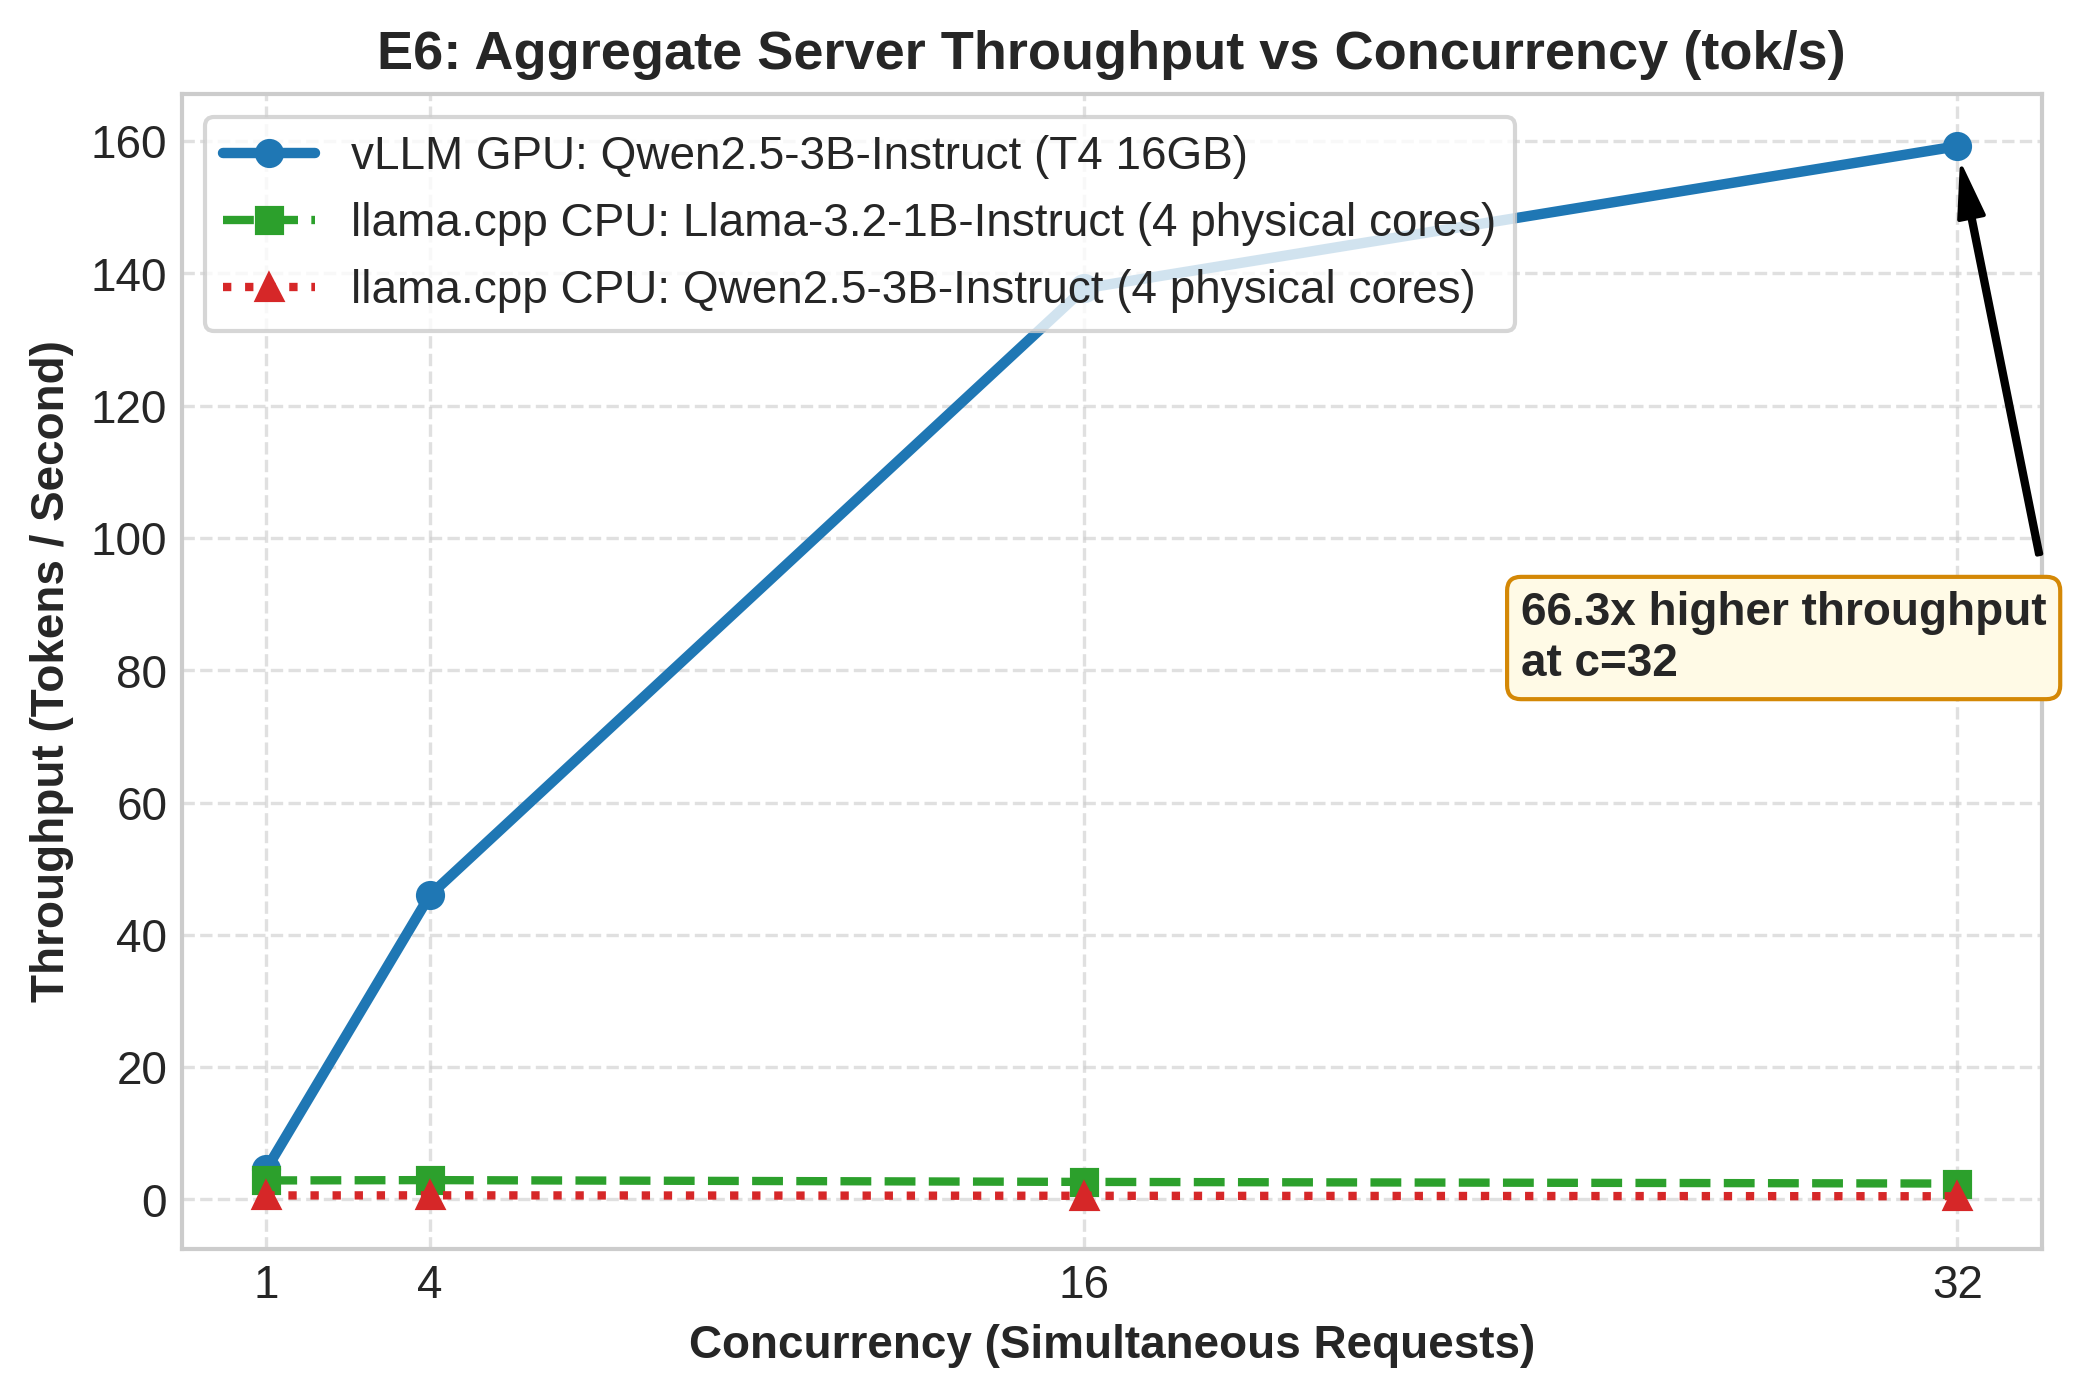

p95 Latency Scaling across Concurrency Levels:


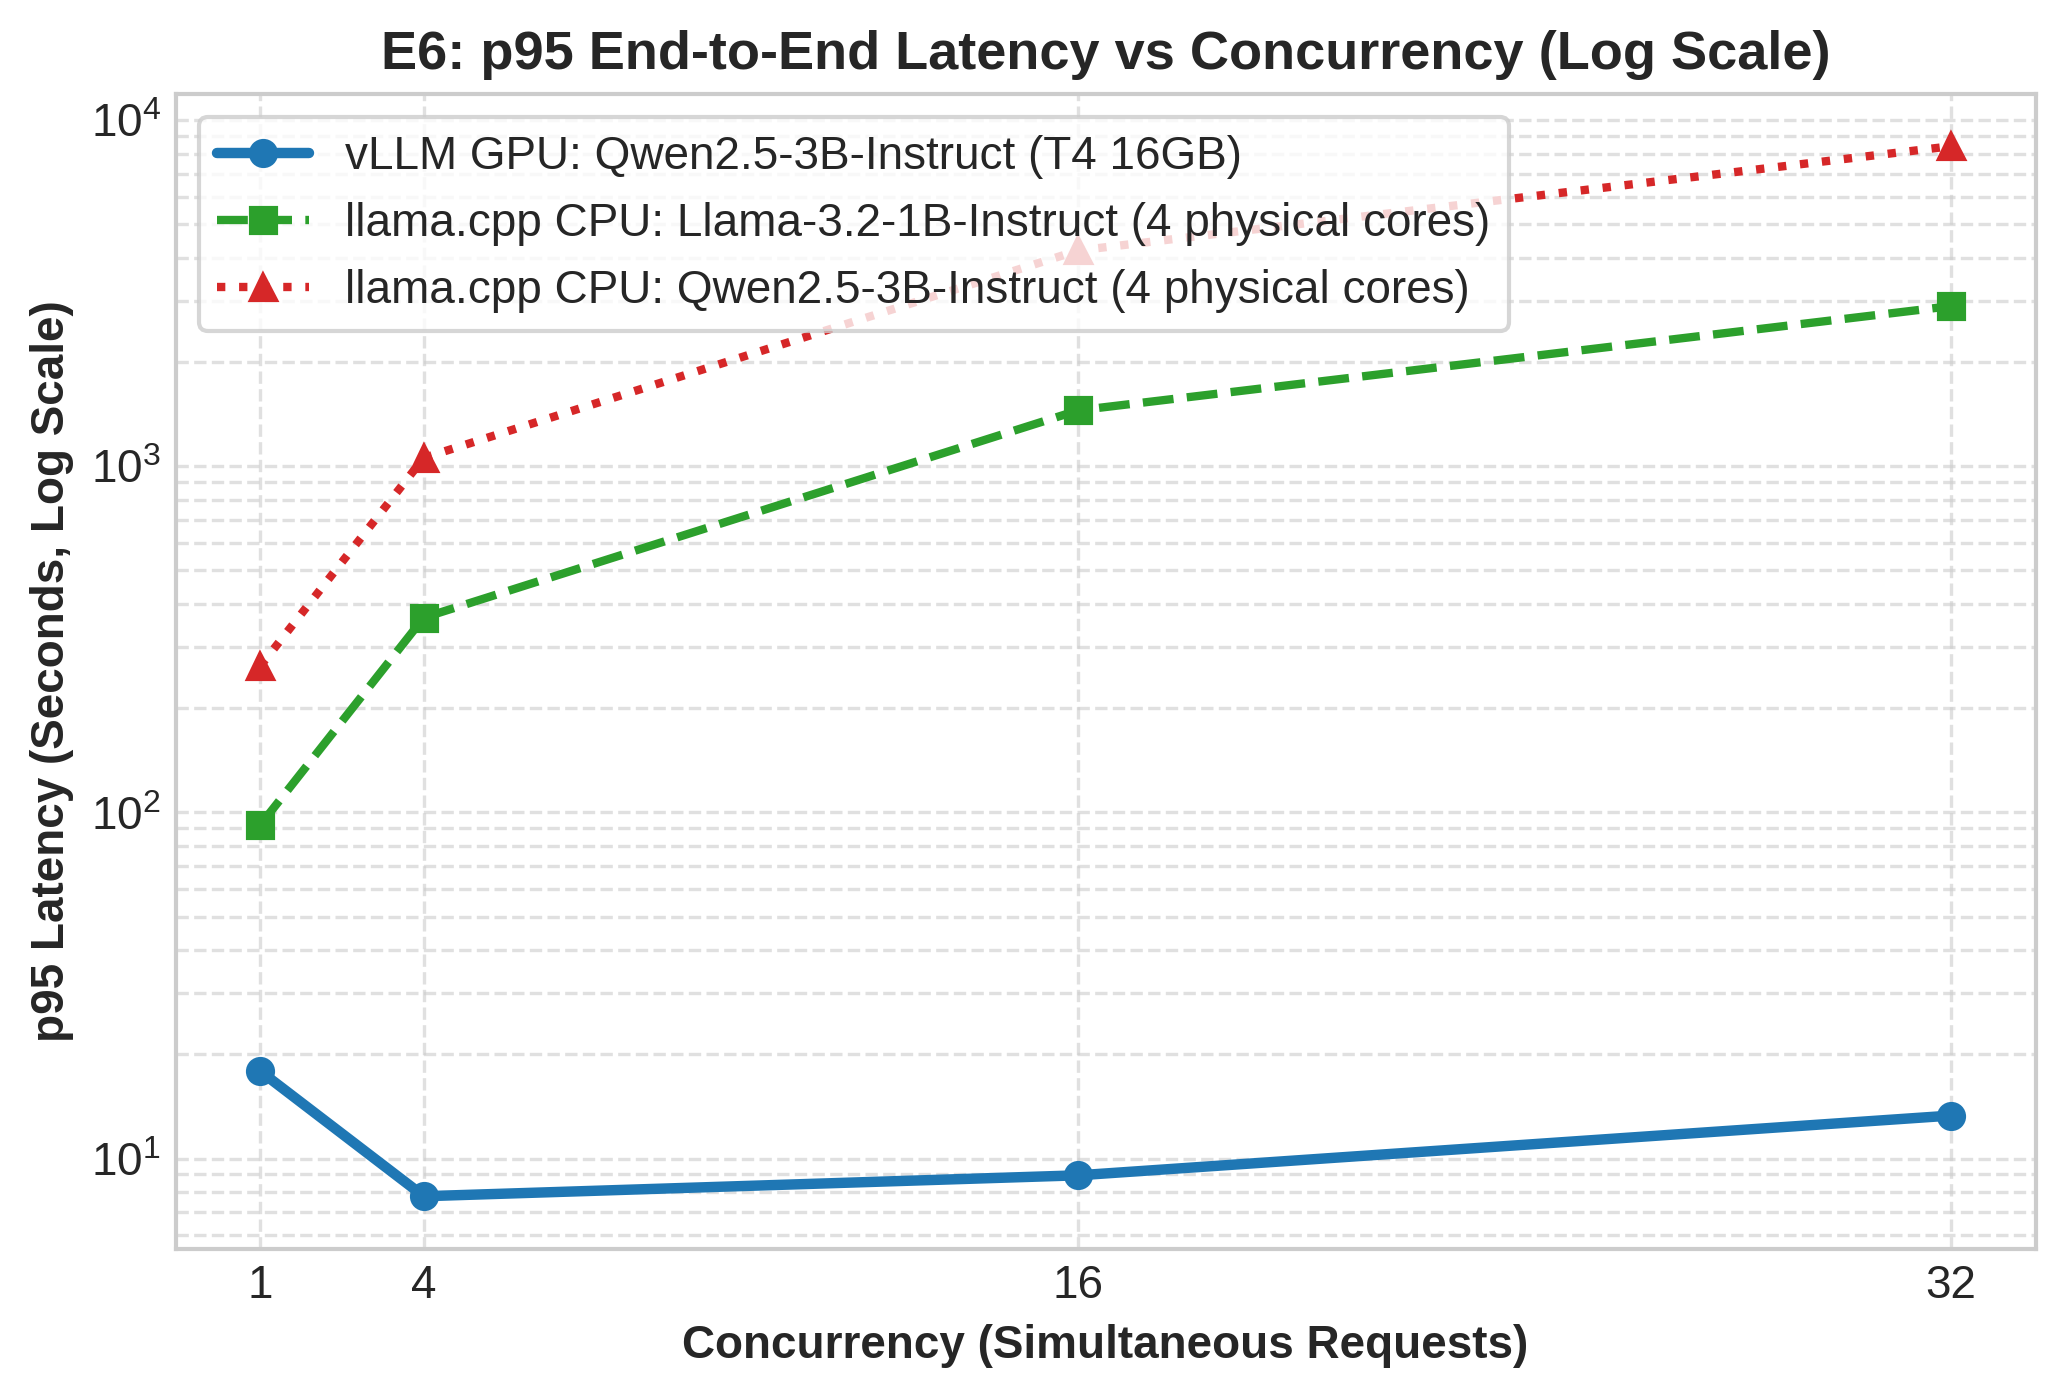

vLLM Time-To-First-Token (TTFT) across Concurrency Levels:


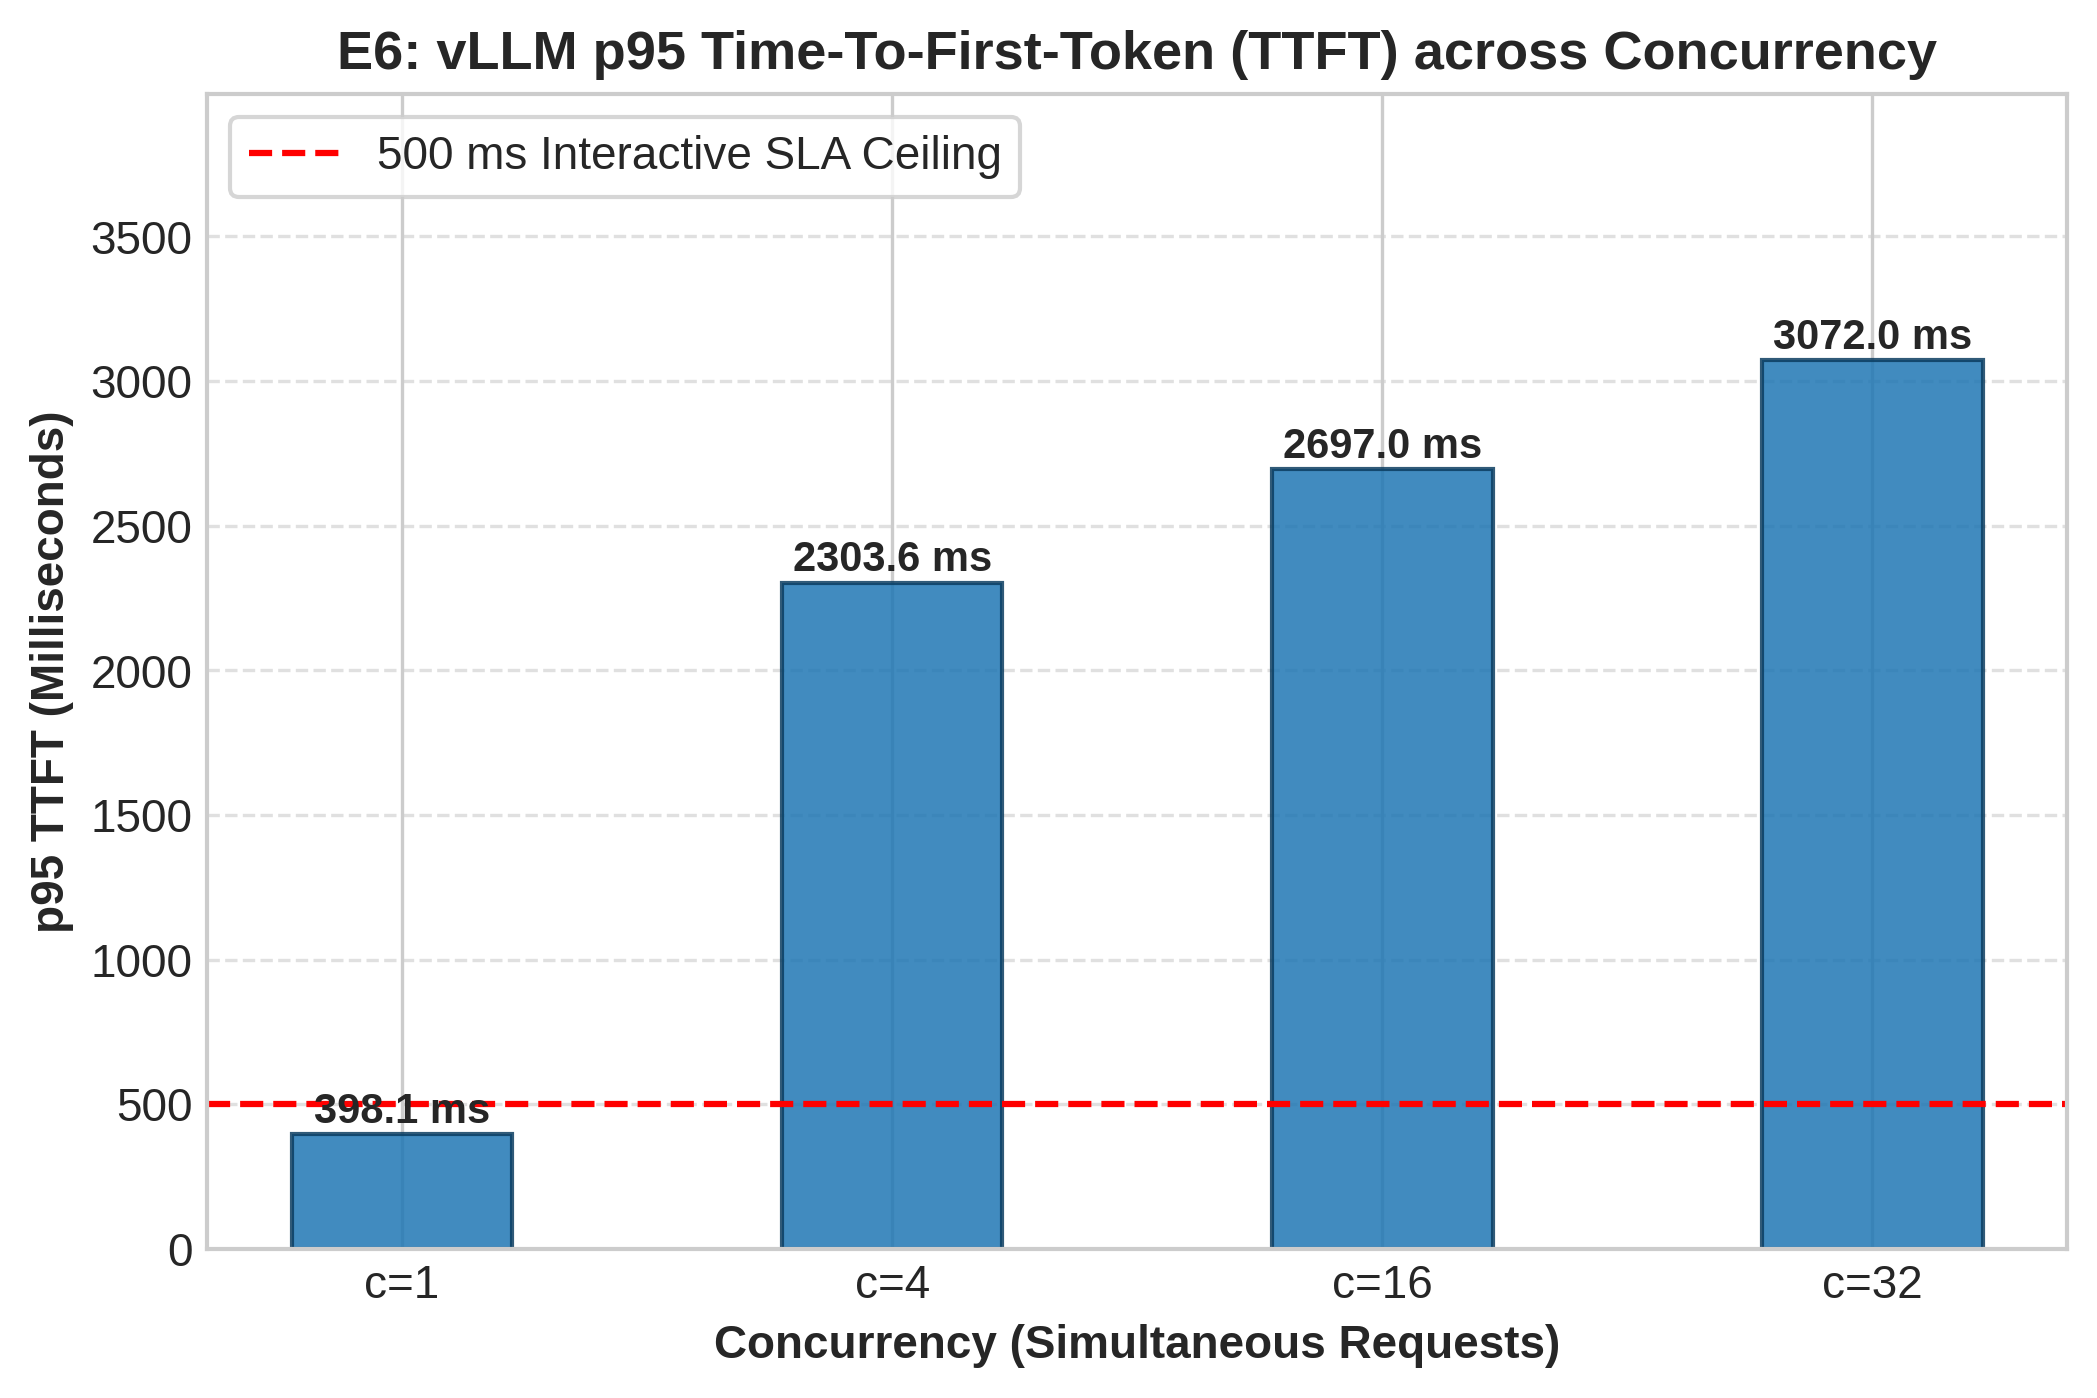

In [6]:
# 6. Render Comparative Performance Visualizations
from IPython.display import Image, display

print("Throughput vs Concurrency (vLLM GPU vs llama.cpp CPU):")
display(Image(filename="docs/assets/e6_throughput_concurrency.png"))

print("p95 Latency Scaling across Concurrency Levels:")
display(Image(filename="docs/assets/e6_latency_p95_concurrency.png"))

print("vLLM Time-To-First-Token (TTFT) across Concurrency Levels:")
display(Image(filename="docs/assets/e6_ttft_scaling.png"))

In [7]:
# 7. Teardown Server
if "server_proc" in locals() and server_proc.poll() is None:
    server_proc.terminate()
    print("vLLM server stopped.")

vLLM server stopped.
